In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
funnel= pd.read_csv(r"C:\Users\Pavni Rastogi\Desktop\product-analytics-case-study\csv-files\funnel-dataframe.csv")

In [4]:
funnel

,stage,users
0,view,1404179
1,addtocart,37722
2,transaction,11719


In [6]:
view_users = funnel.loc[funnel["stage"]=="view", "users"].iloc[0]
cart_users = funnel.loc[funnel["stage"]=="addtocart", "users"].iloc[0]
purchase_users = funnel.loc[funnel["stage"]=="transaction", "users"].iloc[0]

view_to_cart = round(cart_users / view_users * 100, 2)
cart_to_purchase = round(purchase_users / cart_users * 100, 2)
overall_conversion = round(purchase_users / view_users * 100, 2)

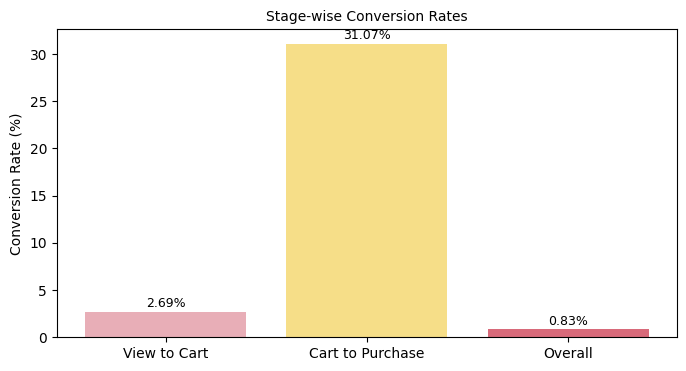

In [20]:
conversion = pd.DataFrame({"Stage": ["View to Cart", "Cart to Purchase", "Overall"],"Conversion Rate (%)": [view_to_cart,cart_to_purchase,overall_conversion]})

plt.figure(figsize=(8,4))
colors = ["#E8AEB7", "#F6DE88", "#D86A7A"]
bars = plt.bar(conversion["Stage"], conversion["Conversion Rate (%)"], color=colors)
for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width()/2,
        h+0.5,
        f"{h:.2f}%",
        ha="center",
        fontsize=9
    )
plt.title("Stage-wise Conversion Rates", fontsize=10)
plt.ylabel("Conversion Rate (%)")
plt.show()

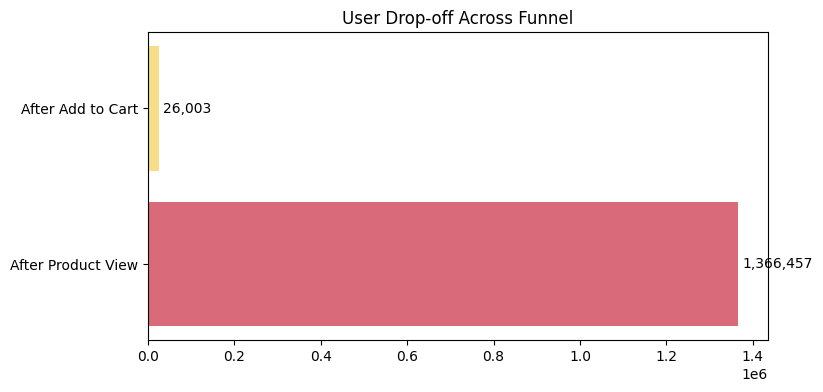

In [21]:
dropoff = pd.DataFrame({"Stage":["After Product View","After Add to Cart"], "Users Lost":[view_users-cart_users, cart_users-purchase_users]})
plt.figure(figsize=(8,4))
colors=["#D86A7A","#F6DE88"]
bars=plt.barh(dropoff["Stage"],dropoff["Users Lost"],color=colors)

for bar in bars:
    w=bar.get_width()
    plt.text(
        w+10000,
        bar.get_y()+bar.get_height()/2,
        f"{w:,.0f}",
        va="center"
    )

plt.title("User Drop-off Across Funnel")
plt.show()

### *summary*

- Around **1.40 million users** viewed at least one product during the analysis period.

- Only **2.69%** of product viewers added an item to their cart, making the **View → Cart** stage the largest bottleneck in the purchase funnel.

- Approximately **1.37 million users** exited immediately after viewing products, indicating significant friction before purchase is established.

- Users who added products to their cart converted to purchase at a much higher rate (**31.07%**), suggesting that checkout is comparatively less problematic than product discovery or product page engagement.

- The overall **View → Purchase conversion rate was 0.83%**, highlighting considerable opportunity to improve user engagement earlier in the customer journey.

### *recommendation*

The platform should prioritize improving the product discovery experience through better recommendations, richer product pages, competitive pricing, and stronger calls-to-action to encourage more users to progress from browsing to adding products to their cart.